In [1]:
from pytweezer.servers.device_client import get_device
from pytweezer.drivers.motmaster import MotMasterInterface
from pytweezer.drivers.imagemX2 import ImagEMX2Camera
from pytweezer.drivers.slm import SLM

In [16]:
slm = get_device("Rb SLM")

In [ ]:
import pytweezer.helper_scripts.phasemask as pm
import numpy as np

In [5]:
dx, dy = 8.0, 12.0
PM = pm.OptimisationBasedPhasemaskGeneratorGPU(
    wavelength_um=0.852,
    focal_length_mm=17.3,
    slm_pitch_um=17,
    slm_res=(1024, 1024),
    input_beam_waist_mm=16,
    fresnel_f_mm=1072,
    blaze_dx_dy_um=(40 + dx, -8 + dy),
    zernike_coeff_dict={
        5: 1.195,
        6: 0.725,
        7: 0.970,
        8: 0.478,
        9: -1.091,
        10: 0.303,
        11: 0.021,
        12: 0.072,
        13: 0.049,
    },
)

--- System Configuration ---
SLM Plane Width: 17.41 mm
SLM Plane Height: 17.41 mm
Focal Plane Resolution x (pixel size): 0.8467 um
Focal Plane Resolution y (pixel size): 0.8467 um
Focal Plane Width: 867.04 um
Focal Plane Height: 867.04 um
Fresnel Lens Focal Length: 1072.00 mm
Blazed Grating Displacement (dx, dy): (48.0, 4.0) um


In [9]:
gauss2d = lambda x, y, A, x0, y0, sx, sy, offset: (
    (A * np.exp(-(((x - x0) ** 2) / (2 * sx**2) + ((y - y0) ** 2) / (2 * sy**2))))
    + offset
)
A, x0, y0, sx, sy, offset = [
    -2.14197604e03,
    -1.11443850e01 - dx,
    2.09919600e00 - dy,
    2.95002910e03,
    2.64281503e03,
    2.14239505e03,
]

In [11]:
W1 = np.ones((15, 15))
spacing_um = 5.0

w_n, theta_n, x_n, y_n = PM.generate_weighted_array(
    W1, spacing_um, init_phase_randomness=1.0, angle_deg=2.5
)
w_n = (
    W1
    * gauss2d(
        x_n.reshape(W1.shape), y_n.reshape(W1.shape), A, x0, y0, sx, sy, offset
    )
).flatten()

terms1 = [w_n, theta_n, x_n, y_n]
pm_array1, terms1, _ = PM.superposition_optimization(
    terms1, max_iter=2000, damping=0.5, verbose=True
)


--- Target Generation ---
Grid: 15x15
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval ---
Iteration 000 | Mean-Squared Error: 4.39e-06 | Uniformity: 38.20% | Min/Max ratio: 0.023
Iteration 010 | Mean-Squared Error: 4.88e-08 | Uniformity: 74.74% | Min/Max ratio: 0.326
Iteration 020 | Mean-Squared Error: 7.95e-09 | Uniformity: 76.24% | Min/Max ratio: 0.360
Iteration 030 | Mean-Squared Error: 3.16e-09 | Uniformity: 75.87% | Min/Max ratio: 0.376
Iteration 040 | Mean-Squared Error: 1.28e-09 | Uniformity: 76.00% | Min/Max ratio: 0.378
Iteration 050 | Mean-Squared Error: 1.19e-09 | Uniformity: 76.06% | Min/Max ratio: 0.386
Iteration 060 | Mean-Squared Error: 5.37e-10 | Uniformity: 76.06% | Min/Max ratio: 0.388
Iteration 070 | Mean-Squared Error: 4.95e-10 | Uniformity: 76.07% | Min/Max ratio: 0.385
Iteration 080 | Mean-Squared Error: 7.13e-10 | Uniformity: 76.07% | Min/Max ratio: 0.384
Iteration 090 | Mean-Squared Error: 7.41e-10 | Uniformity: 76.05% | Min/Max ratio: 0.386
Itera

In [12]:
import matplotlib.pyplot as plt

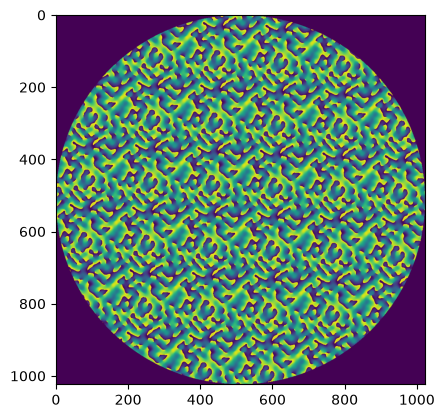

In [13]:
def superimpose_pupil(phasemask, pupil_radius_um, pupil_blaze_dx_dy_um=(0.0, 0.0)):
        """
        Applies a circular pupil function to the phasemask.
        
        Parameters:
        - phasemask (np.ndarray): The input phase mask in radians.
        - pupil_radius_um (float): The radius of the circular pupil in microns.
        - pupil_blaze_dx_dy_um (tuple): The displacement of the pupil from the blaze in microns.
        
        Returns:
        - masked_phasemask (np.ndarray): The phase mask after applying the pupil function.
        """
        X, Y = np.meshgrid(PM.x_slm, PM.y_slm)
        R = np.sqrt(X**2 + Y**2)
        pupil_mask = (R <= pupil_radius_um).astype(float)
        core_mask = (R > pupil_radius_um).astype(float)
        offset_blaze = PM.generate_blazed_grating_phasemask(pupil_blaze_dx_dy_um[0], pupil_blaze_dx_dy_um[1])*core_mask
    
        return phasemask * pupil_mask + offset_blaze

composite_pupil = superimpose_pupil(pm_array1, pupil_radius_um=PM.Lx_slm/2, pupil_blaze_dx_dy_um=(0.0, 0.0))
plt.imshow(composite_pupil.get(), cmap='viridis')

In [27]:
fresnel = PM.generate_fresnel_lens_phasemask(1125)
pm_composite = PM.superimpose([pm_array1, fresnel, PM.blaze])
pm_composite_pupil = superimpose_pupil(pm_composite, pupil_radius_um=PM.Lx_slm/2, pupil_blaze_dx_dy_um=(100.0, 0.0))
pm_composite_uint8 = PM.transform_phase_8bit(pm_composite_pupil).get()
slm.update_mask(pm_composite_uint8)

In [25]:
from pytweezer.experiment.experiment_parameter_manager import ExpParameterManager
import pytweezer.analysis.analysis as an


In [21]:
exp = get_device("Rb MotMaster")
hamcam = get_device("Rb HamCam")
ExpParams = ExpParameterManager()

In [28]:
# Experiment and camera setup
n_iterations = 10
exp.set_motmaster_experiment("RbTweezerBasic2026_2")
exp.set_iterations(n_iterations)
hamcam.setup_acquisition("snap", n_iterations * 2)
hamcam.start_acquisition()
exp.start_motmaster_experiment({
    "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
    "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
    "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"),
    "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
    "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"),
    "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
    "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"),
    "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
    "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
    "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
    "tTweezerSetVVA0": 0.0, "tTweezerSetVVA1": 0.0,
    "BackgroundDrop": 1})

imgs = hamcam.acquire_n_frames(n_iterations * 2)
imgs1, imgs2 = imgs[::2], imgs[1::2]


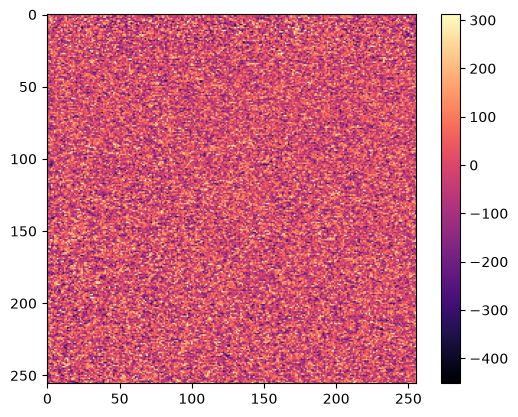

In [30]:
img_average = an.tweezer_show_bg_subtracted(imgs1, imgs2, cmap='magma', show=True, vmaxfactor=0.6, show_grid=True)
